# 04 · Modelo final: a partida vai atrasar mais de 30 min?

Versão final do modelo. Mudanças em relação ao notebook 03:

- **Alvo binário** (até 30 min × mais de 30 min). Com 15 anos de dados, as faixas 30–60 e > 60 continuaram com precisão e recall de 24–40%, então juntamos tudo acima de 30 min (a tolerância usada pela ANAC).
- **Dados de 2011 a 2025**, sem os períodos com dados incompletos ou atípicos (jun–jul/2014, ago/2017–mar/2018, pandemia 2020–2021).
- **Divisão temporal por anos inteiros**: treino até 2022, validação 2023 (hiperparâmetros e limiar do alerta), teste 2024–2025. Dois anos de teste cobrem todas as estações duas vezes.

O treino pesado roda fora do notebook (`uv run python -m module_decea.exportar_web`, ~16 GB de RAM, ou o workflow *Treinar modelo final* no GitHub Actions). Este notebook só lê o relatório gerado em `reports/modelo_final/resumo.json`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
r = json.loads((raiz / "reports/modelo_final/resumo.json").read_text())
NOME = {"vespera": "Véspera", "h3": "3 h antes", "h1": "1 h antes"}
print(r["gerado_em"], "|", r["alvo"])
pd.Series(r["periodos"]).to_frame("período").join(pd.Series(r["n"]).rename("partidas"), how="left")

2026-10-15T13:22:59+00:00 | partida com atraso > 30 min


,período,partidas
treino,2011–2022,3210082
validacao,2023,480293
teste,2024–2025,973986


## Desempenho no teste (2024–2025)

- **PR-AUC**: qualidade do ranking de risco, sem depender de limiar. O chute vale a proporção de atrasos (~8%).
- **Precisão / recall / F1**: no limiar escolhido em 2023 para maximizar o F1.

In [2]:
linhas = {"Chute": r["chute"]} | {NOME[k]: r["modelos"][k] for k in ["vespera", "h3", "h1"]}
cols = ["ROC-AUC", "PR-AUC", "log_loss", "limiar", "precisão", "recall", "F1", "% voos com alerta"]
pd.DataFrame(linhas).T.reindex(columns=cols).astype(float).round(3)

,ROC-AUC,PR-AUC,log_loss,limiar,precisão,recall,F1,% voos com alerta
Chute,0.500,0.080,0.278,NaN,NaN,0.000,0.000,0.000
Véspera,0.698,0.194,0.258,0.12,0.193,0.366,0.253,0.151
3 h antes,0.733,0.256,0.247,0.15,0.262,0.343,0.298,0.104
1 h antes,0.786,0.367,0.227,0.19,0.377,0.402,0.389,0.085


## Pontos de operação

Melhor precisão possível para cada fração dos atrasos que se quer avisar. Mais recall custa mais alarmes falsos.

In [3]:
pd.DataFrame({NOME[k]: {f"recall {p['recall']:.0%}": p["precisão"] for p in r["modelos"][k]["pontos_operacao"]}
              for k in ["vespera", "h3", "h1"]}).round(3)

,Véspera,3 h antes,1 h antes
recall 20%,0.260,0.373,0.610
recall 30%,0.215,0.290,0.483
recall 40%,0.183,0.235,0.378
recall 50%,0.160,0.196,0.295
recall 60%,0.141,0.166,0.230


## Matriz de confusão (% de cada linha, 1 h antes)

In [4]:
pd.DataFrame(r["modelos"]["h1"]["confusao"], index=["real: até 30 min", "real: > 30 min"],
             columns=["sem alerta", "alerta"]).round(1)

,sem alerta,alerta
real: até 30 min,94.2,5.8
real: > 30 min,59.8,40.2


## Sazonalidade: mês a mês em 2024–2025

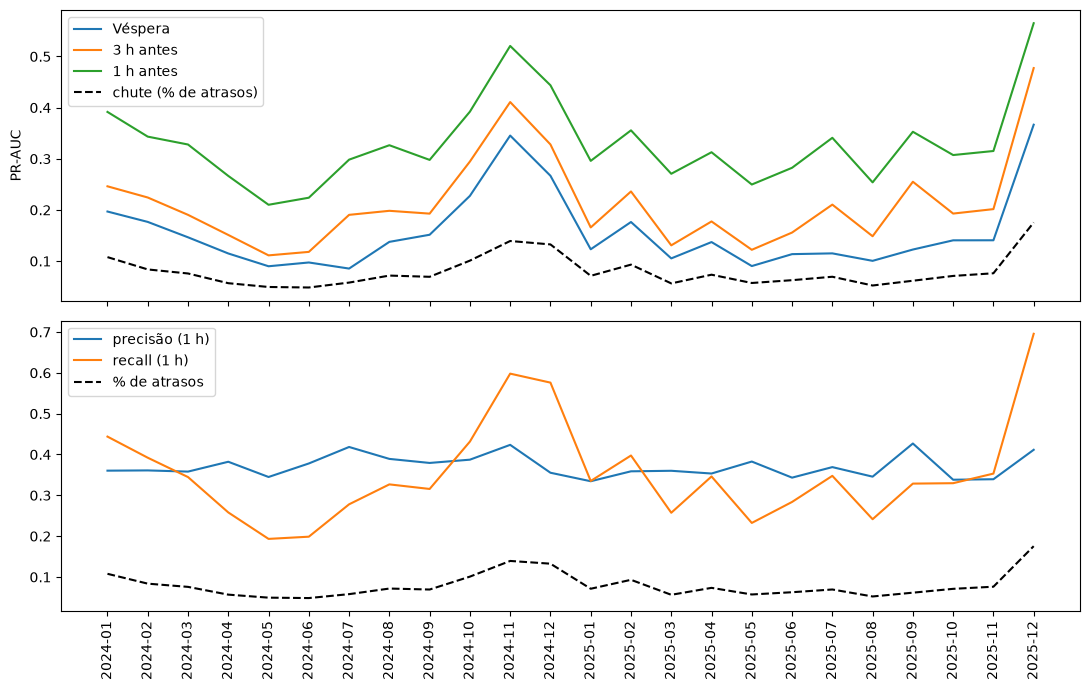

In [5]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for k in ["vespera", "h3", "h1"]:
    m = pd.DataFrame(r["mensal"][k])
    a1.plot(m["mes"], m["pr_auc"], label=NOME[k])
m = pd.DataFrame(r["mensal"]["h1"])
a1.plot(m["mes"], m["prevalencia"], "k--", label="chute (% de atrasos)")
a1.set_ylabel("PR-AUC"); a1.legend()
a2.plot(m["mes"], m["precisao"], label="precisão (1 h)")
a2.plot(m["mes"], m["recall"], label="recall (1 h)")
a2.plot(m["mes"], m["prevalencia"], "k--", label="% de atrasos")
a2.legend(); a2.tick_params(axis="x", rotation=90)
plt.tight_layout()

A precisão fica relativamente estável ao longo do ano; o recall acompanha a taxa de atrasos do mês (meses com mais atrasos, como dezembro, são mais fáceis de prever).

## Quanto histórico usar

Mesmo modelo de 1 h e mesmo teste, variando só os anos de treino.

In [6]:
pd.DataFrame(r["janelas"]).set_index("janela")

,voos_treino,pr_auc,log_loss
janela,,,
desde 2011 (meses válidos),3690375,0.3673,0.2267
desde abr/2018,1795993,0.3703,0.2262
só 2023,480293,0.3650,0.2277


## O que o modelo usa (importância por permutação, 1 h antes)

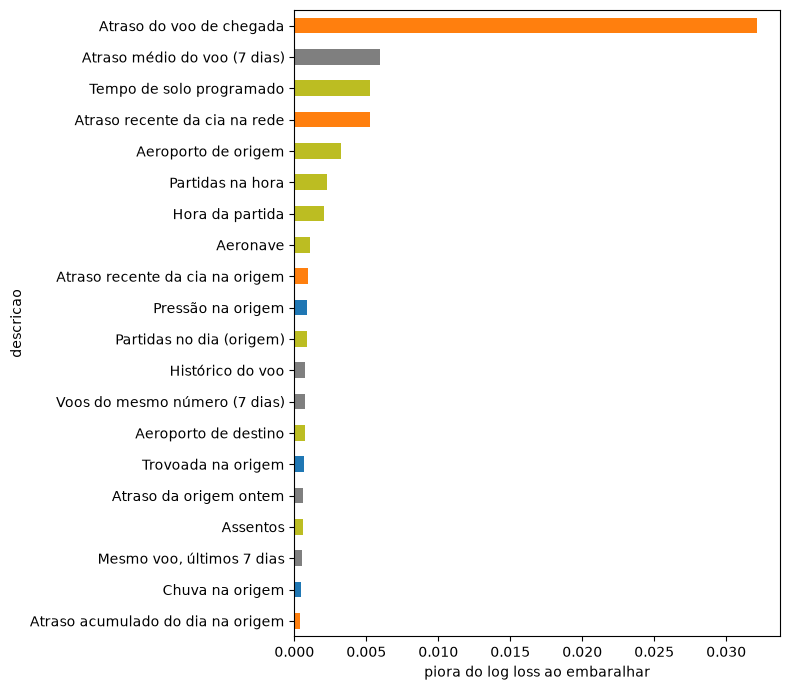

In [7]:
imp = pd.DataFrame(r["importancia"]).set_index("descricao")
imp["valor"].sort_values().plot.barh(figsize=(8, 7), color=imp.sort_values("valor")["grupo"].map(
    {"propagação": "C1", "clima": "C0", "histórico": "C7", "programação": "C8"}))
plt.xlabel("piora do log loss ao embaralhar"); plt.tight_layout()

## Taxa de atraso > 30 min por ano

In [8]:
pd.DataFrame(r["eda"]["por_ano"]).set_index("chave")

,taxa30,voos
chave,,
2011,0.0988,398443
2012,0.0806,421786
2013,0.0763,414613
2014,0.0775,345537
2015,0.0532,314003
2018,0.0747,381095
2019,0.0715,500266
2022,0.0614,434339
2023,0.0838,480293
